In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
db=pd.read_csv("Diabetes.csv")

In [4]:
#Select features for clustering
X = db.drop("Outcome", axis=1)

print("Selected features:")
print(X.columns.tolist())

print("\nShape of data:")
print(X.shape)

Selected features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Shape of data:
(768, 8)


In [5]:
#Invalid values
invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[invalid_columns] = X[invalid_columns].replace(0, np.nan)

for column in invalid_columns:
    X[column] = X[column].fillna(X[column].median())

print("Missing values after preprocessing:")
print(X.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [6]:
#Standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature standardization completed successfully.")
print("Standardized data shape:", X_scaled.shape)

Feature standardization completed successfully.
Standardized data shape: (768, 8)


In [7]:
#Apply K-Means for different values of K
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print("Inertia values:")
for k, value in zip(range(2, 11), inertia):
    print(f"K = {k}: {value:.2f}")

Inertia values:
K = 2: 4919.65
K = 3: 4273.43
K = 4: 3901.41
K = 5: 3667.62
K = 6: 3462.67
K = 7: 3294.96
K = 8: 3134.47
K = 9: 2979.40
K = 10: 2859.98


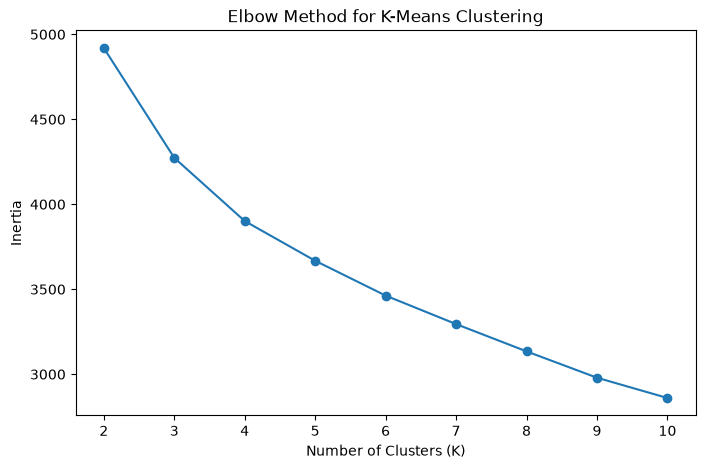

In [8]:
#Plot the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker='o')

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))

plt.show()

In [9]:
for k, value in zip(range(2, 11), inertia):
    print(f"K = {k}, Inertia = {value:.2f}")

print("\nBased on the decrease in inertia, K = 3 or K = 4 appears to be a possible elbow.")

K = 2, Inertia = 4919.65
K = 3, Inertia = 4273.43
K = 4, Inertia = 3901.41
K = 5, Inertia = 3667.62
K = 6, Inertia = 3462.67
K = 7, Inertia = 3294.96
K = 8, Inertia = 3134.47
K = 9, Inertia = 2979.40
K = 10, Inertia = 2859.98

Based on the decrease in inertia, K = 3 or K = 4 appears to be a possible elbow.


In [10]:
#Apply K-Means with K = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed successfully.")
print("Number of clusters:", len(np.unique(clusters)))

print("\nCluster counts:")
print(pd.Series(clusters).value_counts().sort_index())

K-Means clustering completed successfully.
Number of clusters: 4

Cluster counts:
0    238
1    291
2    196
3     43
Name: count, dtype: int64


In [11]:
#Calculate the Silhouette Score
silhouette = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.19081324890058285


In [12]:
#This indicates that the clusters have some separation, but there is 
#considerable overlap between them. So, the 4 clusters are not very strongly separated.

In [13]:
#Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA completed successfully.")
print("Reduced data shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained:")
print(pca.explained_variance_ratio_.sum())

PCA completed successfully.
Reduced data shape: (768, 2)

Explained variance ratio:
[0.29817668 0.18752573]

Total variance explained:
0.48570240530469533


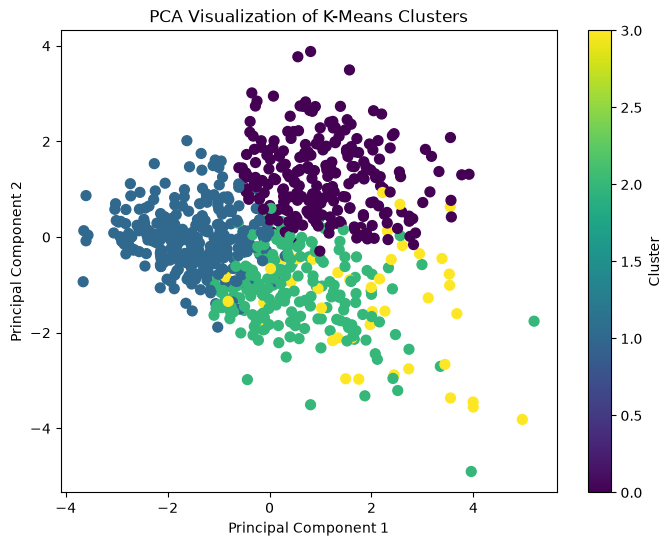

In [14]:
#PCA Cluster Visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.title("PCA Visualization of K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

In [15]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = clusters

print("Cluster positions in PCA space:")
print(
    pca_df.groupby("Cluster")[["PC1", "PC2"]]
    .mean()
    .round(2)
)

Cluster positions in PCA space:
          PC1   PC2
Cluster            
0        1.04  1.24
1       -1.50 -0.04
2        0.52 -1.14
3        1.99 -1.34


In [16]:
#Compare Clusters with Diabetes Outcome
comparison = pd.crosstab(
    clusters,
    db["Outcome"],
    rownames=["Cluster"],
    colnames=["Outcome"]
)

print("Cluster vs Outcome:")
print(comparison)

Cluster vs Outcome:
Outcome    0    1
Cluster          
0        115  123
1        262   29
2        104   92
3         19   24
